In [5]:
import pandas as pd

df = pd.read_csv("xAPI-Edu-Data.csv")
df.head()

,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M


In [ ]:
# Select only the pre-assessment behavioural features
behavioural_features = ['raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion']

X = df[behavioural_features].copy()
X.head()


,raisedhands,VisITedResources,AnnouncementsView,Discussion
0,15,16,2,20
1,20,20,3,25
2,10,7,0,30
3,30,25,5,35
4,40,50,12,50


In [ ]:
# Convert Class into binary: 1 = At-Risk, 0 = Pass
y = df['Class'].apply(lambda x: 1 if x in ['L', 'M'] else 0)

# Check the distribution
print("Target distribution:")
print(y.value_counts())
print("\nProportions:")
print(y.value_counts(normalize=True).round(3))

Target distribution:
Class
1    338
0    142
Name: count, dtype: int64

Proportions:
Class
1    0.704
0    0.296
Name: proportion, dtype: float64


In [ ]:
# Create an Engagement Index: the average of the four behavioural indicators
X['Engagement_Index'] = (
    X['raisedhands'] +
    X['VisITedResources'] +
    X['AnnouncementsView'] +
    X['Discussion']
) / 4

# Show the updated table
X.head()

,raisedhands,VisITedResources,AnnouncementsView,Discussion,Engagement_Index
0,15,16,2,20,13.25
1,20,20,3,25,17.00
2,10,7,0,30,11.75
3,30,25,5,35,23.75
4,40,50,12,50,38.00


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set size: (384, 5)
Testing set size: (96, 5)

Training target distribution:
Class
1    0.703
0    0.297
Name: proportion, dtype: float64

Testing target distribution:
Class
1    0.708
0    0.292
Name: proportion, dtype: float64


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Fit the scaler on training data only, then apply to both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Scaling complete.")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Scaling complete.
Training shape: (384, 5)
Testing shape: (96, 5)


In [ ]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())
print("\nClass values:\n", df['Class'].value_counts())

Shape: (480, 17)

Columns: ['gender', 'NationalITy', 'PlaceofBirth', 'StageID', 'GradeID', 'SectionID', 'Topic', 'Semester', 'Relation', 'raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion', 'ParentAnsweringSurvey', 'ParentschoolSatisfaction', 'StudentAbsenceDays', 'Class']

Missing values:
 gender                      0
NationalITy                 0
PlaceofBirth                0
StageID                     0
GradeID                     0
SectionID                   0
Topic                       0
Semester                    0
Relation                    0
raisedhands                 0
VisITedResources            0
AnnouncementsView           0
Discussion                  0
ParentAnsweringSurvey       0
ParentschoolSatisfaction    0
StudentAbsenceDays          0
Class                       0
dtype: int64

Class values:
 Class
M    211
H    142
L    127
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Create and train the model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [ ]:
lr_results = {
    'Accuracy':  round(accuracy_score(y_test, y_pred_lr), 4),
    'Precision': round(precision_score(y_test, y_pred_lr), 4),
    'Recall':    round(recall_score(y_test, y_pred_lr), 4),
    'F1-Score':  round(f1_score(y_test, y_pred_lr), 4)
}

print("Logistic Regression Results:")
for metric, value in lr_results.items():
    print(f"  {metric}: {value}")

Logistic Regression Results:
  Accuracy: 0.7917
  Precision: 0.8429
  Recall: 0.8676
  F1-Score: 0.8551


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create and train the Decision Tree
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train_scaled, y_train)

# Predict
y_pred_dt = dt_model.predict(X_test_scaled)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [ ]:
dt_results = {
    'Accuracy':  round(accuracy_score(y_test, y_pred_dt), 4),
    'Precision': round(precision_score(y_test, y_pred_dt), 4),
    'Recall':    round(recall_score(y_test, y_pred_dt), 4),
    'F1-Score':  round(f1_score(y_test, y_pred_dt), 4)
}

print("Decision Tree Results:")
for metric, value in dt_results.items():
    print(f"  {metric}: {value}")

Decision Tree Results:
  Accuracy: 0.7917
  Precision: 0.8158
  Recall: 0.9118
  F1-Score: 0.8611


In [ ]:
import pandas as pd

# Build the results table
results_df = pd.DataFrame([
    {'Model': 'Logistic Regression', **lr_results},
    {'Model': 'Decision Tree', **dt_results}
])
results_df = results_df.set_index('Model')
print(results_df)

# Save to file
results_df.to_csv("classification_results.csv")
print("\nSaved to classification_results.csv")

                     Accuracy  Precision  Recall  F1-Score
Model                                                     
Logistic Regression    0.7917     0.8429  0.8676    0.8551
Decision Tree          0.7917     0.8158  0.9118    0.8611

Saved to classification_results.csv


In [ ]:
import pandas as pd

# Get the column names (features)
feature_names = X.columns

# Extract coefficients
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lr_model.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False)

print("Logistic Regression Coefficients:")
print(coef_df)

Logistic Regression Coefficients:
             Feature  Coefficient
1   VisITedResources    -2.120373
0        raisedhands    -2.046918
4   Engagement_Index    -1.227675
3         Discussion    -0.502657
2  AnnouncementsView     0.217736


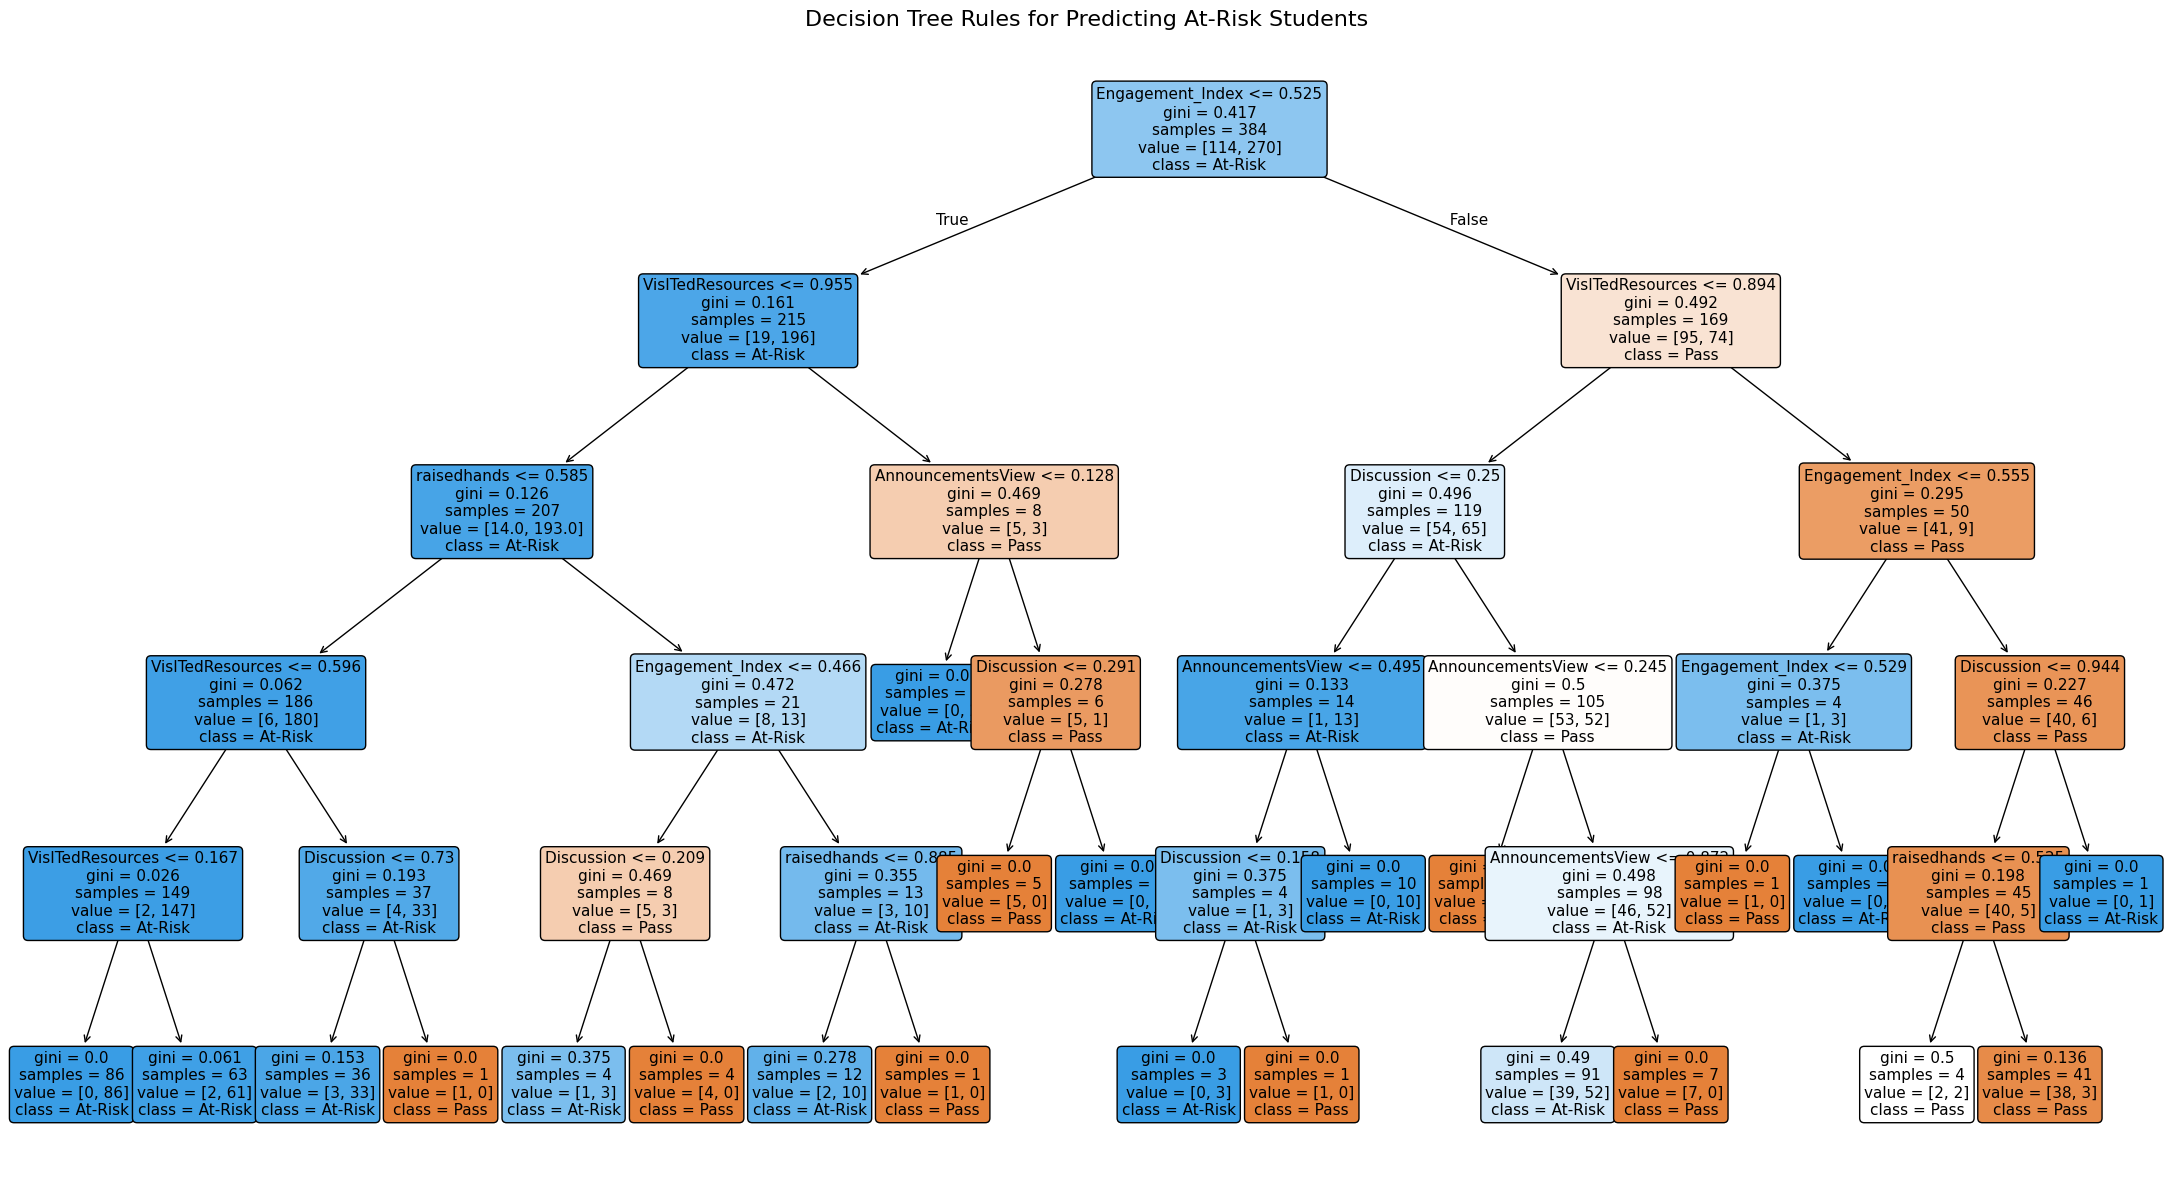

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 12))
plot_tree(
    dt_model,
    feature_names=feature_names,
    class_names=['Pass', 'At-Risk'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Decision Tree Rules for Predicting At-Risk Students", fontsize=16)
plt.tight_layout()
plt.savefig("decision_tree_rules.png", dpi=200)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("Decision Tree Feature Importance:")
print(importance_df)

Decision Tree Feature Importance:
             Feature  Importance
4   Engagement_Index    0.514399
1   VisITedResources    0.157853
3         Discussion    0.140858
2  AnnouncementsView    0.110289
0        raisedhands    0.076602


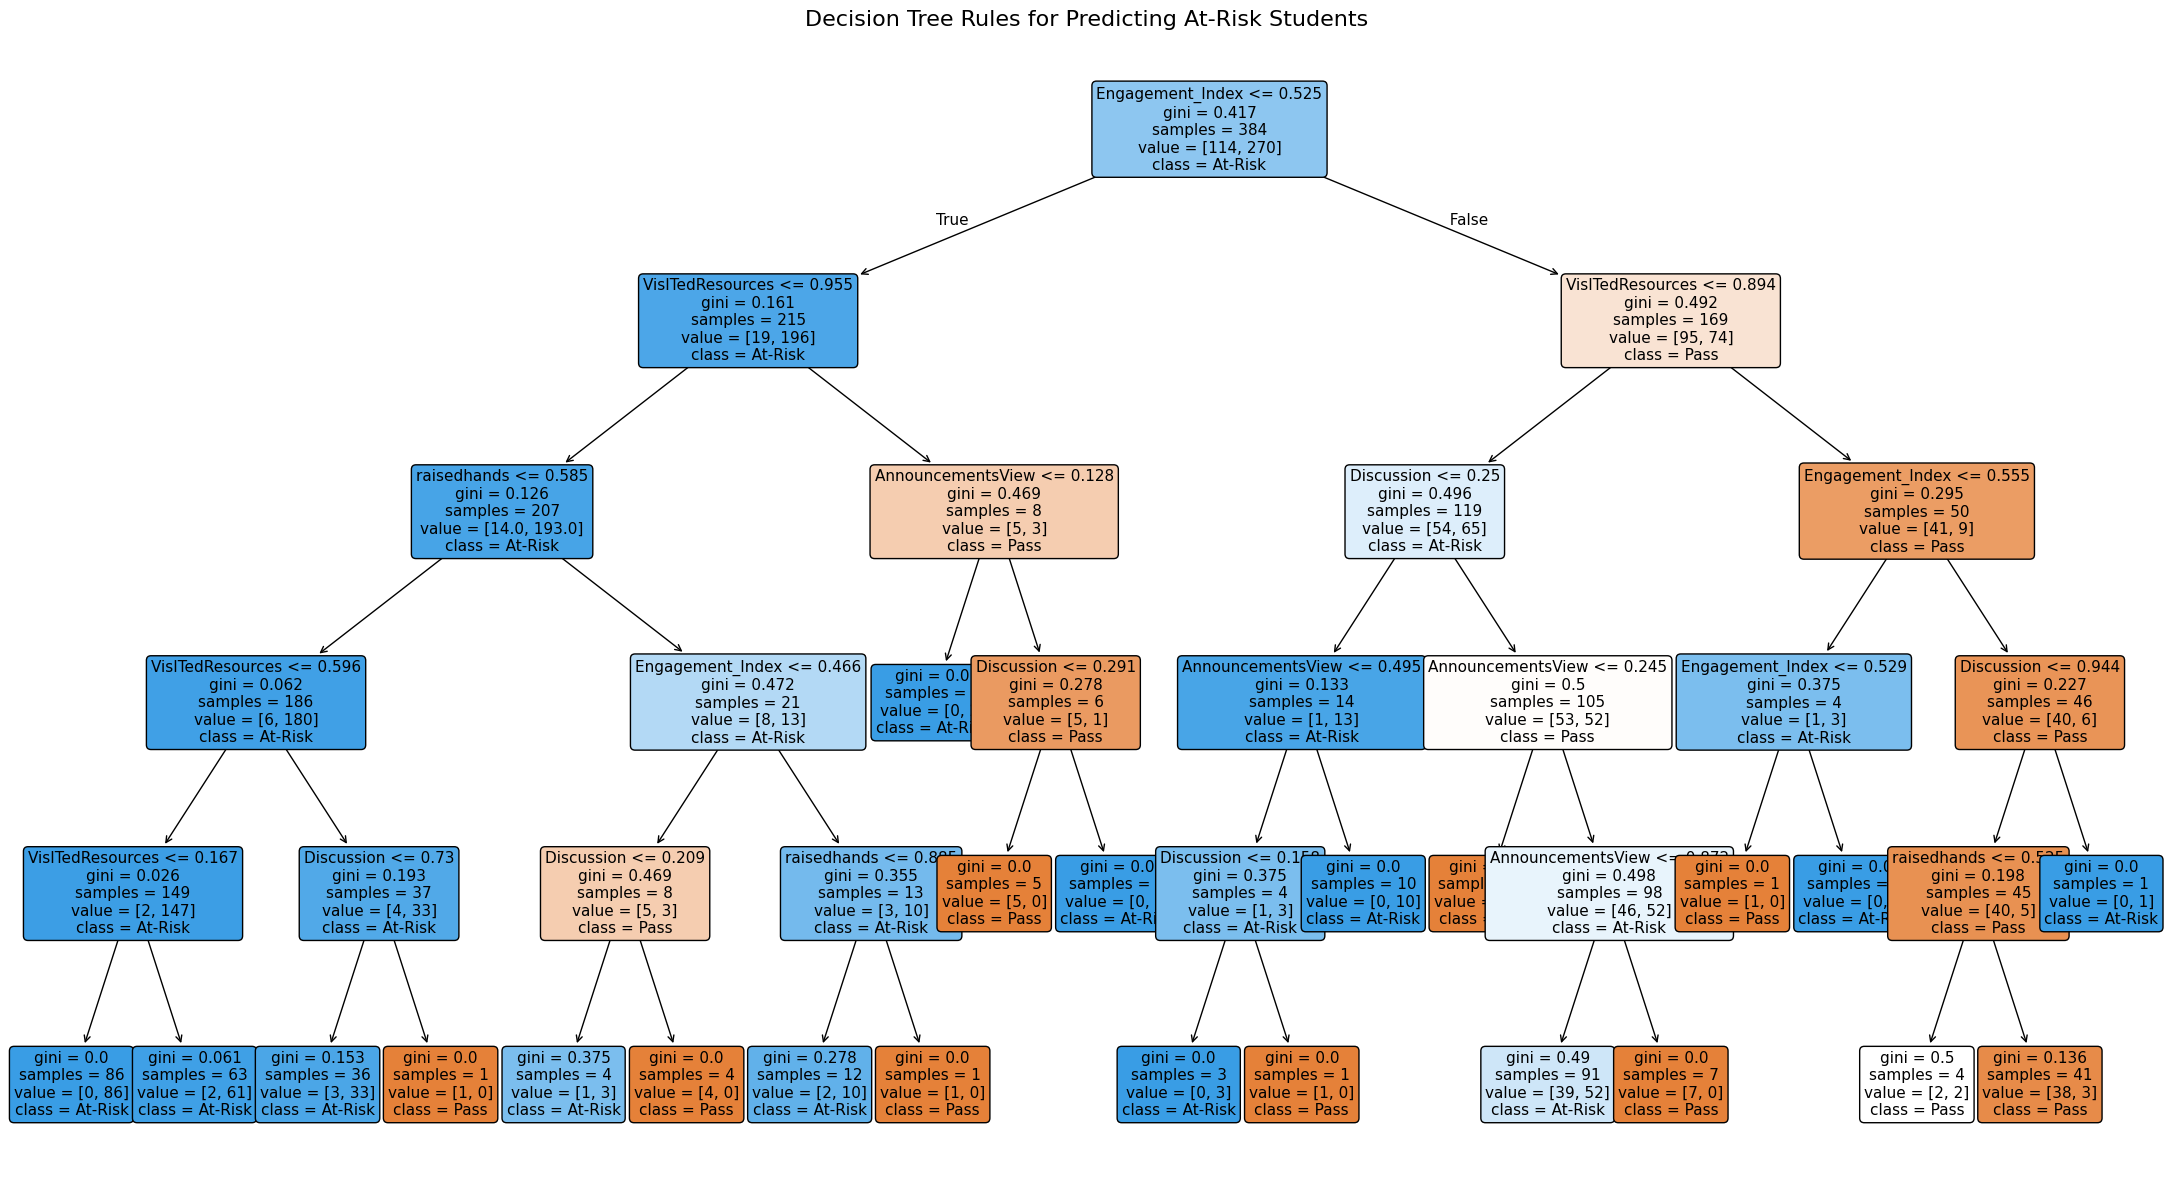

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 12))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=['Pass', 'At-Risk'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Decision Tree Rules for Predicting At-Risk Students", fontsize=16)
plt.tight_layout()
plt.savefig("decision_tree_rules.png", dpi=200)
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
print("LR Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))
print("\nDT Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

LR Confusion Matrix:
[[17 11]
 [ 9 59]]

DT Confusion Matrix:
[[14 14]
 [ 6 62]]


In [ ]:
import pandas as pd

df = pd.read_csv("xAPI-Edu-Data.csv")
df.head()

,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M


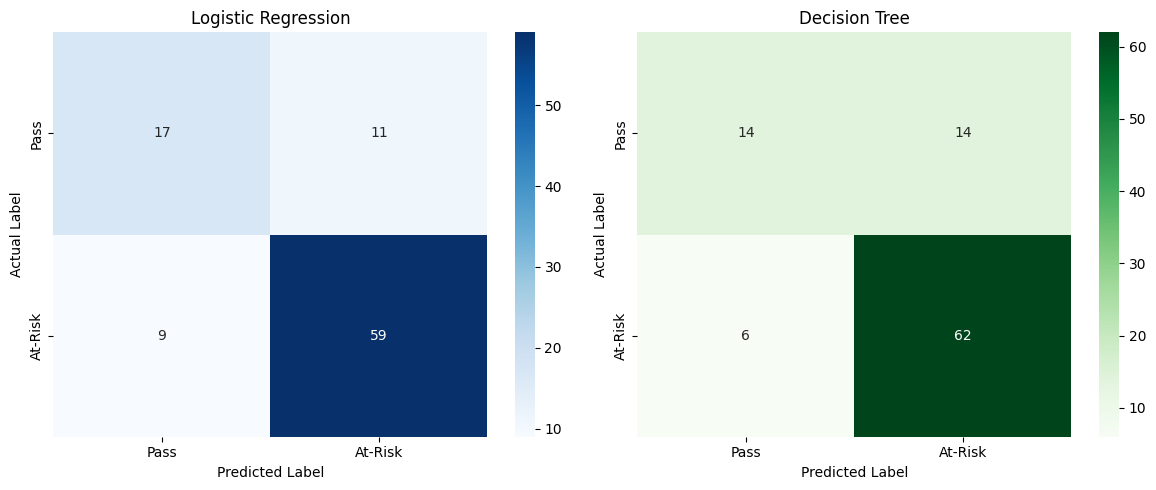

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix

# 1. Reconstruct dataset and preprocessing
df = pd.read_csv("xAPI-Edu-Data.csv")
behavioural_features = ['raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion']
X = df[behavioural_features].copy()

# Create Engagement Index
X['Engagement_Index'] = (
    X['raisedhands'] +
    X['VisITedResources'] +
    X['AnnouncementsView'] +
    X['Discussion']
) / 4

# Convert Class to binary: 1 = At-Risk, 0 = Pass
y = df['Class'].apply(lambda x: 1 if x in ['L', 'M'] else 0)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Re-train models and get predictions
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train_scaled, y_train)
y_pred_dt = dt_model.predict(X_test_scaled)

# 3. Generate confusion matrices plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pass', 'At-Risk'],
            yticklabels=['Pass', 'At-Risk'], ax=axes[0])
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Decision Tree Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Pass', 'At-Risk'],
            yticklabels=['Pass', 'At-Risk'], ax=axes[1])
axes[1].set_title('Decision Tree')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()

# Save the figure
plt.savefig("Figure_2_Confusion_Matrices.png", dpi=300)
plt.show()

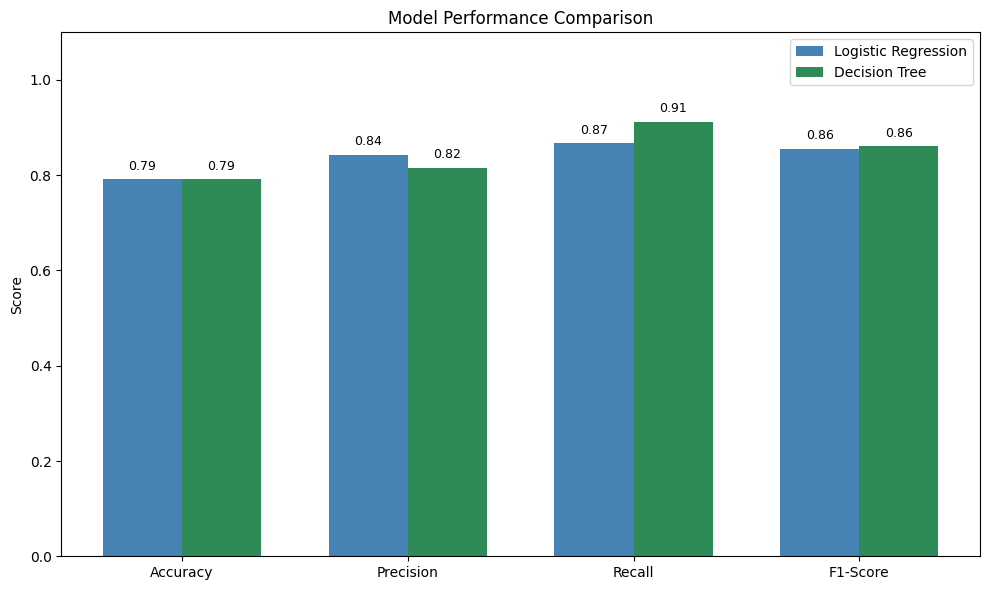

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
lr_scores = [0.7917, 0.8429, 0.8676, 0.8551]
dt_scores = [0.7917, 0.8158, 0.9118, 0.8611]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, lr_scores, width, label='Logistic Regression', color='steelblue')
ax.bar(x + width/2, dt_scores, width, label='Decision Tree', color='seagreen')

ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.legend()

for i, v in enumerate(lr_scores):
    ax.text(i - width/2, v + 0.02, f'{v:.2f}', ha='center', fontsize=9)
for i, v in enumerate(dt_scores):
    ax.text(i + width/2, v + 0.02, f'{v:.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig("Figure_3_Performance_Comparison.png", dpi=300)
plt.show()